This notebook uses strong and weak constraint 4D-Var method to assimilate the KdV system:

$u_{t} + \delta^2 u_{xxx} + \dfrac{1}{2}(u^2)_x$ = 0

In [ ]:
import os
import torch
from matplotlib import pyplot as plt
from tensordict import TensorDict
from time import time
from NLADV.advect_solver import NonlinAdv1D
from NLADV.time_stepping import ETDRK2
os.chdir('..')
from adda.variational.strong_constraint_4dvar import sc4dvar_single_window
from adda.variational.weak_constraint_4dvar import wc4dvar_single_window
from adda.system.state import State
from adda.util.visualization import show_1dseqimg
from adda.observation.operators import random_sparse_noisy_obs
from adda.util.initialization import naive_initialization
from adda.probability.distributions import DiagonalGaussian

# Generation of groundtruth data

In [ ]:
torch.backends.cudnn.deterministic = True
torch.manual_seed(42)

# Experiment parameters
domain_size = 2.0
num_spat = 512
dt = 0.001

# These are the coefficients for the linear terms of the KdV equation.
coeffs = [0, 0, 0, -0.022**2]
# Exponential Time Differencing Runge-Kutta 2nd order (ETDRK2).
integrator = ETDRK2
# We are choosing a long time window to test the strong constraint 4D-Var because the system is not chaotic.
tot_timesteps = 10000

# Create the solver object, which will be used as the forward operator in the 4D-Var optimization and data generation.
forward_operator = NonlinAdv1D(domain_size=domain_size, num_spat=num_spat, dt=dt, linear_coeffs=coeffs, advect_coeff=1.0, integrator=integrator)

In [ ]:
mesh = torch.linspace(0.0, domain_size, num_spat+1)[:-1]
# Cosine wave with wavelength equal to the domain size, as the time progresses, this wave will break into solitons.
initial_state = torch.cos(torch.pi * mesh)
initial_state = initial_state.unsqueeze(0)
forecast_steps = torch.arange(0, tot_timesteps * dt, dt)
# Generated ground truth data by integrating the initial state forward in time.
kdv_series = forward_operator.integrate(time=forecast_steps, state=initial_state).squeeze()

torch.Size([10000, 512])


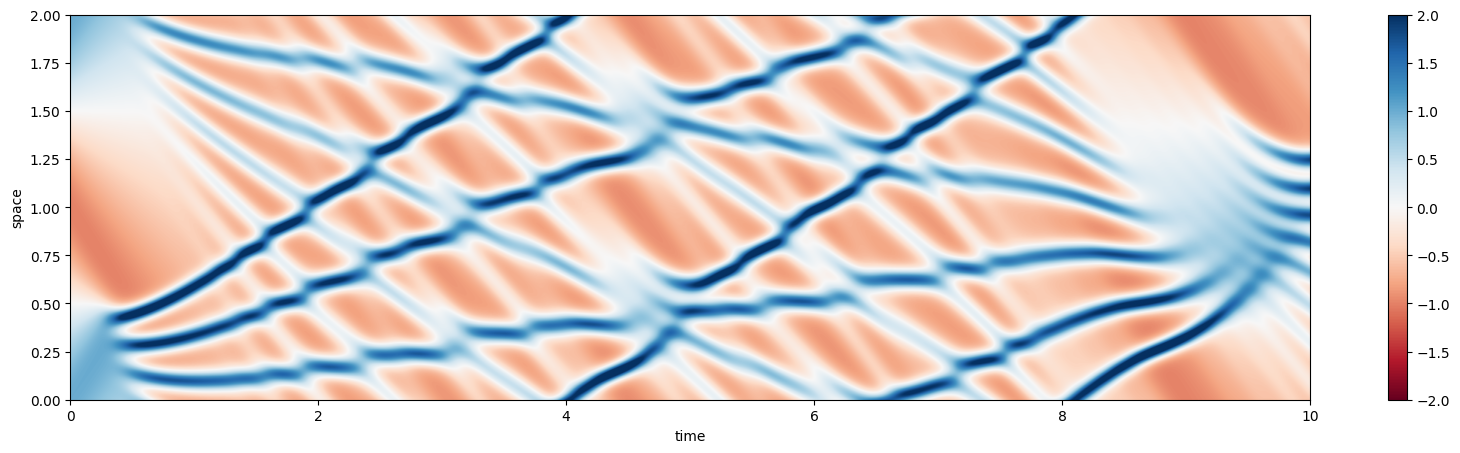

In [ ]:
# Cutoff applied to the beginning of the series to remove the initial transient stage.
# Since the system is not chaotic, we choose it as 0 to keep the full series.
cutoff = 0

ctrj = kdv_series[cutoff:, :].numpy()
plt.figure(figsize=(20, 5))
plt.imshow(
    ctrj.transpose(),
    cmap="RdBu",
    aspect="auto",
    origin="lower",
    extent=(0, ctrj.shape[0] * dt, 0, domain_size),
    vmin=-2,
    vmax=2,
)
plt.colorbar()
plt.xlabel("time")
plt.ylabel("space")
print(kdv_series[cutoff:, :].shape)

In [ ]:
true_initial_state = kdv_series[0]
forecast_steps = torch.arange(0, (tot_timesteps - cutoff) * dt, dt)
true_series = State(kdv_series.reshape(1, -1, num_spat), time_axis=forecast_steps)

Text(0.5, 1.0, 'Initial Ground Truth State of the KdV System')

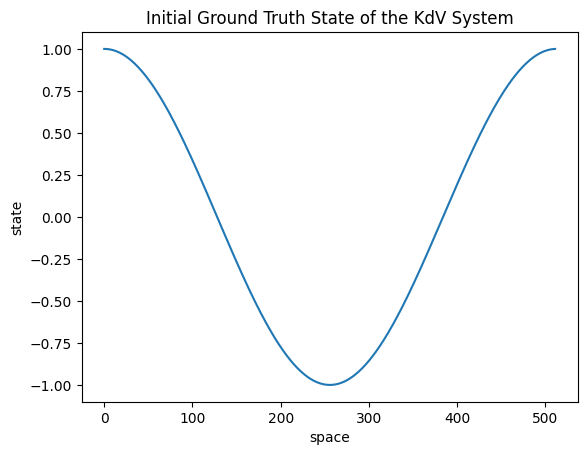

In [ ]:
plt.plot(true_initial_state)
plt.xlabel("space")
plt.ylabel("state")
plt.title("Initial Ground Truth State of the KdV System")

In [ ]:
# In order to use the 4D-Var function, you should always have a function like this taking the state, dt, dynamic_inputs and static_inputs
def next_step_function(x: State, dt: float, dynamic_inputs: State, static_inputs: State):
    B, T = x.fields.batch_size[:2]
    input = x.fields["x"].reshape(B * T, num_spat)
    integrated = forward_operator.integrate(torch.arange(2) * dt, input)[:, -2:-1] # integrate over a time step, take the current time
    integrated = integrated.reshape(B, T, num_spat)
    new_fields = TensorDict(x=integrated, batch_size=(B, T))
    return State(new_fields, time_axis=x.time_axis + dt)  # return State object, advancing time

# Strong-constraint 4D-var

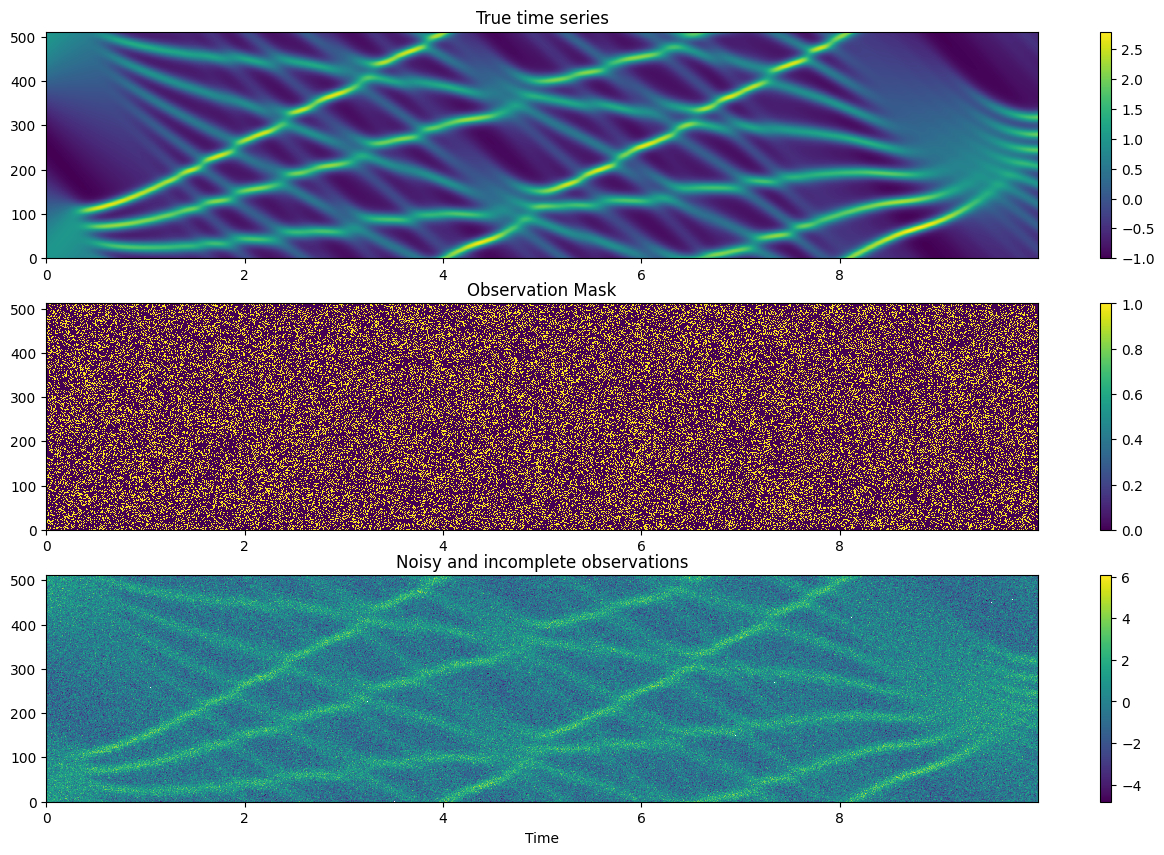

In [ ]:
noise_amplitude = 1.0  # observation noise s.d.
p_obs = 0.25 # 75% of the variables are masked

groundtruth, obs_op, observations = random_sparse_noisy_obs(true_series, noise_amplitude, p_obs)

valid_obs = observations.state.fields['x'][0].T
valid_obs[torch.logical_not(observations.mask.fields['x'][0].T)] = torch.nan
fig, ax = plt.subplots(3, 1, figsize=(16,10))

show_1dseqimg(true_series.fields['x'][0].T, dt=dt, ax=ax[0], title="True time series")
show_1dseqimg(observations.mask.fields['x'][0].T, dt=dt, ax=ax[1], title="Observation Mask")
show_1dseqimg(valid_obs, dt=dt, ax=ax[2], title="Noisy and incomplete observations", x_label="Time")

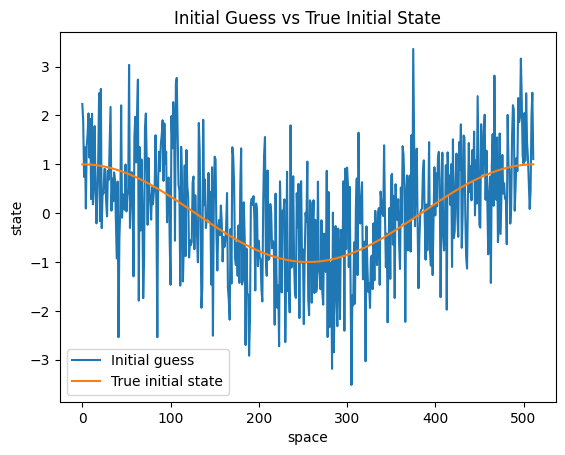

In [ ]:
initialization = naive_initialization(observations)  # state estimate for all time points
initialization = initialization[:, :1]  # first time point only

plt.plot(initialization.fields['x'].squeeze(), label='Initial guess')
plt.plot(true_series.fields['x'].squeeze()[0], label='True initial state')
plt.legend()
plt.title("Initial Guess vs True Initial State")
plt.xlabel("space")
plt.ylabel("state")
plt.show()

In [ ]:
n_obs_steps = 200 # Time steps to assimilate.
time_window = (observations.state.time_axis[0], observations.state.time_axis[n_obs_steps])

obs_op_opt = obs_op.restrict_time_domain(*time_window)
observations_opt = observations.restrict_time_domain(*time_window)

In [ ]:
t0 = time()
assimilated_ic = sc4dvar_single_window(next_step_function, 
                                       observations_opt, 
                                       obs_op_opt, 
                                       initialization,                                        
                                       optimizer_pars={'lr': 1e-1},
                                       verbose=1,
                                       n_steps=5)                                     
print(f'Total time for the 4D-Var optimization: {time() - t0} seconds')

iteration 0: loss = 54237.85546875
iteration 0: loss = 54221.84375
iteration 0: loss = 49947.65625
iteration 0: loss = 45120.67578125
iteration 0: loss = 41154.171875
iteration 0: loss = 38230.5703125
iteration 0: loss = 35790.68359375
iteration 0: loss = 33714.94140625
iteration 0: loss = 32211.1484375
iteration 0: loss = 30937.41796875
iteration 0: loss = 29884.85546875
iteration 0: loss = 28968.283203125
iteration 0: loss = 28183.515625
iteration 0: loss = 27530.576171875
iteration 0: loss = 26997.7265625
iteration 0: loss = 26555.748046875
iteration 0: loss = 26188.216796875
iteration 0: loss = 25889.98046875
iteration 0: loss = 25653.21484375
iteration 0: loss = 25468.6953125
iteration 1: loss = 25325.849609375
iteration 1: loss = 25214.953125
iteration 1: loss = 25128.12109375
iteration 1: loss = 25059.46484375
iteration 1: loss = 25004.623046875
iteration 1: loss = 24960.4609375
iteration 1: loss = 24924.658203125
iteration 1: loss = 24895.4921875
iteration 1: loss = 24871.64843

In [ ]:
# We generate the trajectories from the assimilated initial condition and the initial guess to see how they compare with the true trajectory.
assim_input = assimilated_ic.fields['x'].reshape(1, num_spat)
initialization_input = initialization.fields['x'].reshape(1, num_spat)
assimilated_trajectory = forward_operator.integrate(time=forecast_steps, state=assim_input).squeeze()
trajectories_from_initial_guess = forward_operator.integrate(time=forecast_steps, state=initialization_input).squeeze()

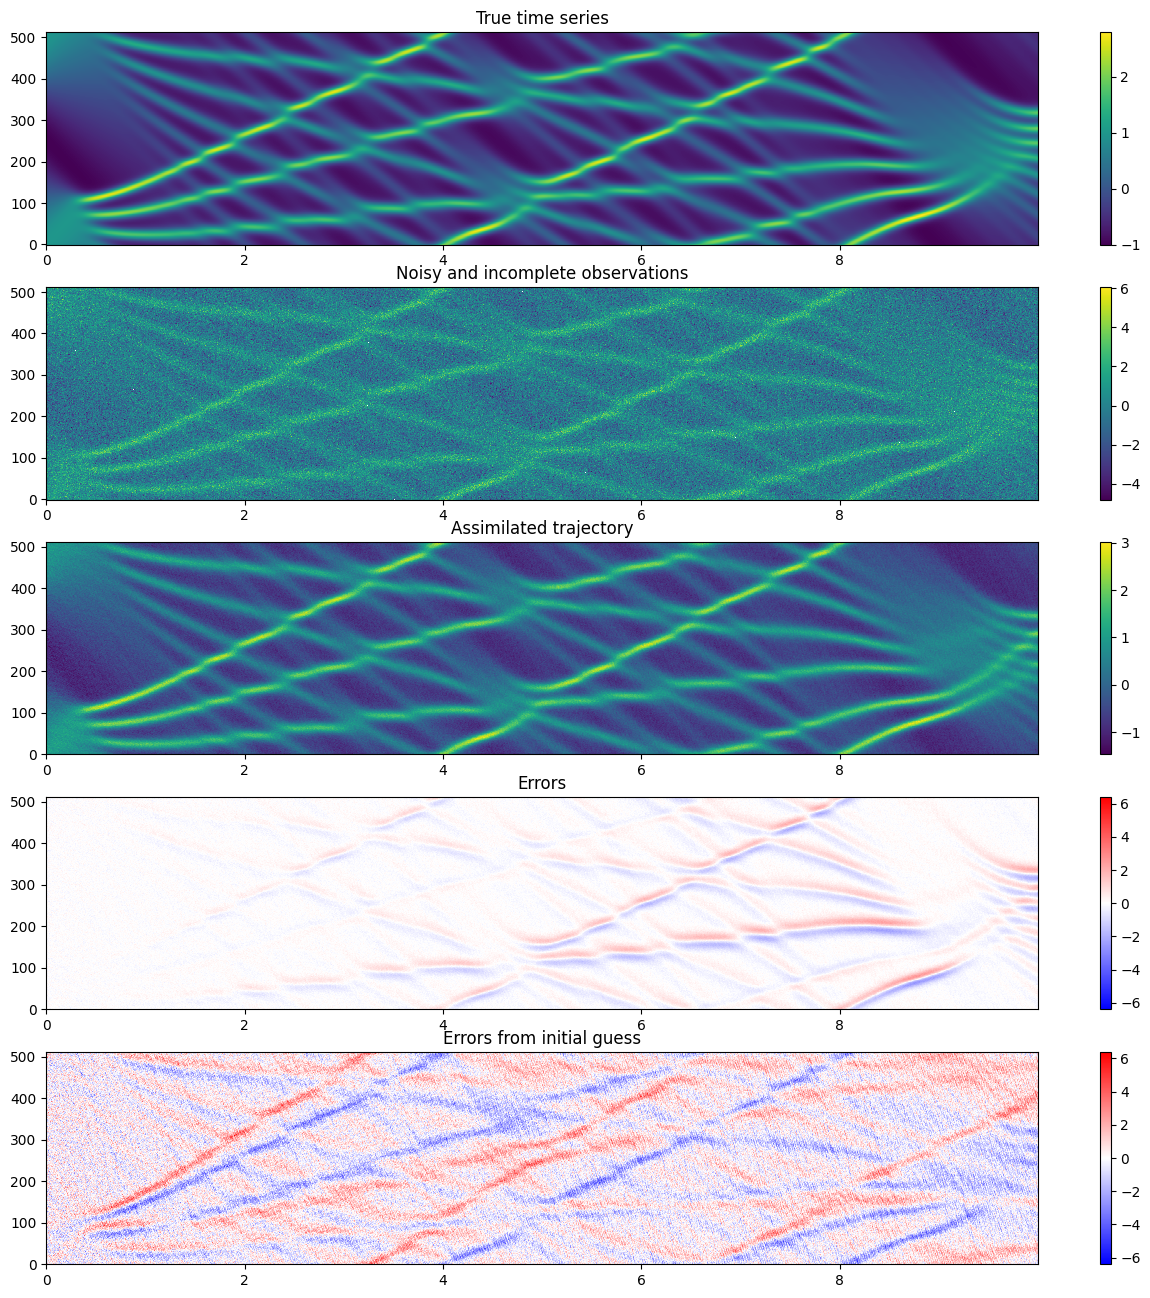

In [ ]:
# We visualize the errors of the assimilated trajectory and the trajectory from the initial guess.
error = assimilated_trajectory.detach() - true_series.fields['x']
error_2 = trajectories_from_initial_guess.detach() - true_series.fields['x']
fig, ax = plt.subplots(5, 1, figsize=(16,16))
show_1dseqimg(true_series.fields['x'][0].T, dt=dt, ax=ax[0], title="True time series")
show_1dseqimg(valid_obs, dt=dt, ax=ax[1], title="Noisy and incomplete observations")
show_1dseqimg(assimilated_trajectory.detach().T, dt=dt, ax=ax[2], title="Assimilated trajectory")
show_1dseqimg(error.detach().squeeze().T, dt=dt, ax=ax[3], title="Errors", cmap="bwr", vmin=-torch.max(torch.abs(error_2)), vmax=torch.max(torch.abs(error_2)))
show_1dseqimg(error_2.detach().squeeze().T, dt=dt, ax=ax[4], title="Errors from initial guess", cmap="bwr", vmin=-torch.max(torch.abs(error_2)),  vmax=torch.max(torch.abs(error_2)))

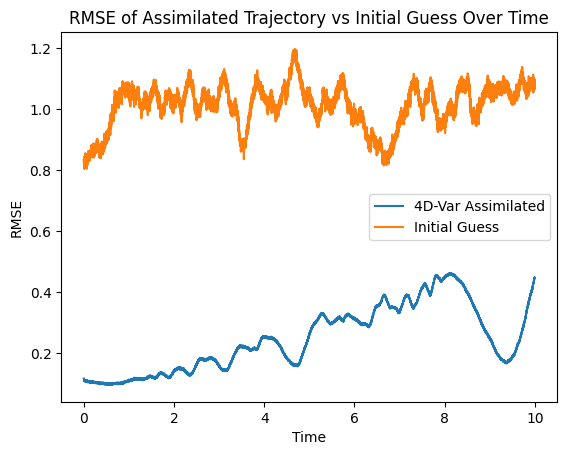

In [ ]:
# We can also plot the RMSE of the assimilated trajectory and the trajectory from the initial guess over time.
RMSE_over_time_assimilated = torch.mean(torch.sqrt((error.squeeze().T ** 2)), dim=0)
RMSE_over_time_initial = torch.mean(torch.sqrt((error_2.squeeze().T ** 2)), dim=0)

fig, ax = plt.subplots()
plt.plot(forecast_steps, RMSE_over_time_assimilated.squeeze(), label='4D-Var Assimilated')
plt.plot(forecast_steps, RMSE_over_time_initial.squeeze(), label='Initial Guess')
ax.set_xlabel('Time')
ax.set_ylabel('RMSE')
plt.legend()
plt.title("RMSE of Assimilated Trajectory vs Initial Guess Over Time")
plt.show()

# Weak-Constraint 4D-Var

In [ ]:
n_steps = true_series.time_axis.nelement()
print(n_steps)
# We define a diagonal Gaussian with mean 0 and standard deviation 1 for the model error distribution, this will be used in the weak-constraint 4D-Var optimization to allow for model errors.
model_error_distribs = DiagonalGaussian(TensorDict({'x': torch.zeros(1, n_steps - 1, num_spat)}), 
                                        TensorDict({'x': torch.ones(1, n_steps - 1, num_spat)}))

10000


In [ ]:
noise_amplitude = 1 # the standard deviation of the noise is 1
obs_proportion = 0.05 # We are making the problem more difficult by reducing the proportion of observed variables to 5%

true_ts, obs_op, observations = random_sparse_noisy_obs(true_series, noise_amplitude, obs_proportion)
valid_obs = observations.state.fields['x'][0].T

In [ ]:
initialization = naive_initialization(observations)  # state estimate for all time points

In [ ]:
t0 = time()
assimilated_states = wc4dvar_single_window(next_step_function, 
                                          observations, 
                                          obs_op, 
                                          model_error_distribs,
                                          x_init=initialization, 
                                          optimizer_pars={'lr': 1},
                                          alpha=1e4,
                                          n_steps=50,
                                          verbose=0)                                       
print(f'Total time for the 4D-Var optimization: {time() - t0} seconds')

assimilated_states = assimilated_states.detach()

Total time for the 4D-Var optimization: 519.9243597984314 seconds


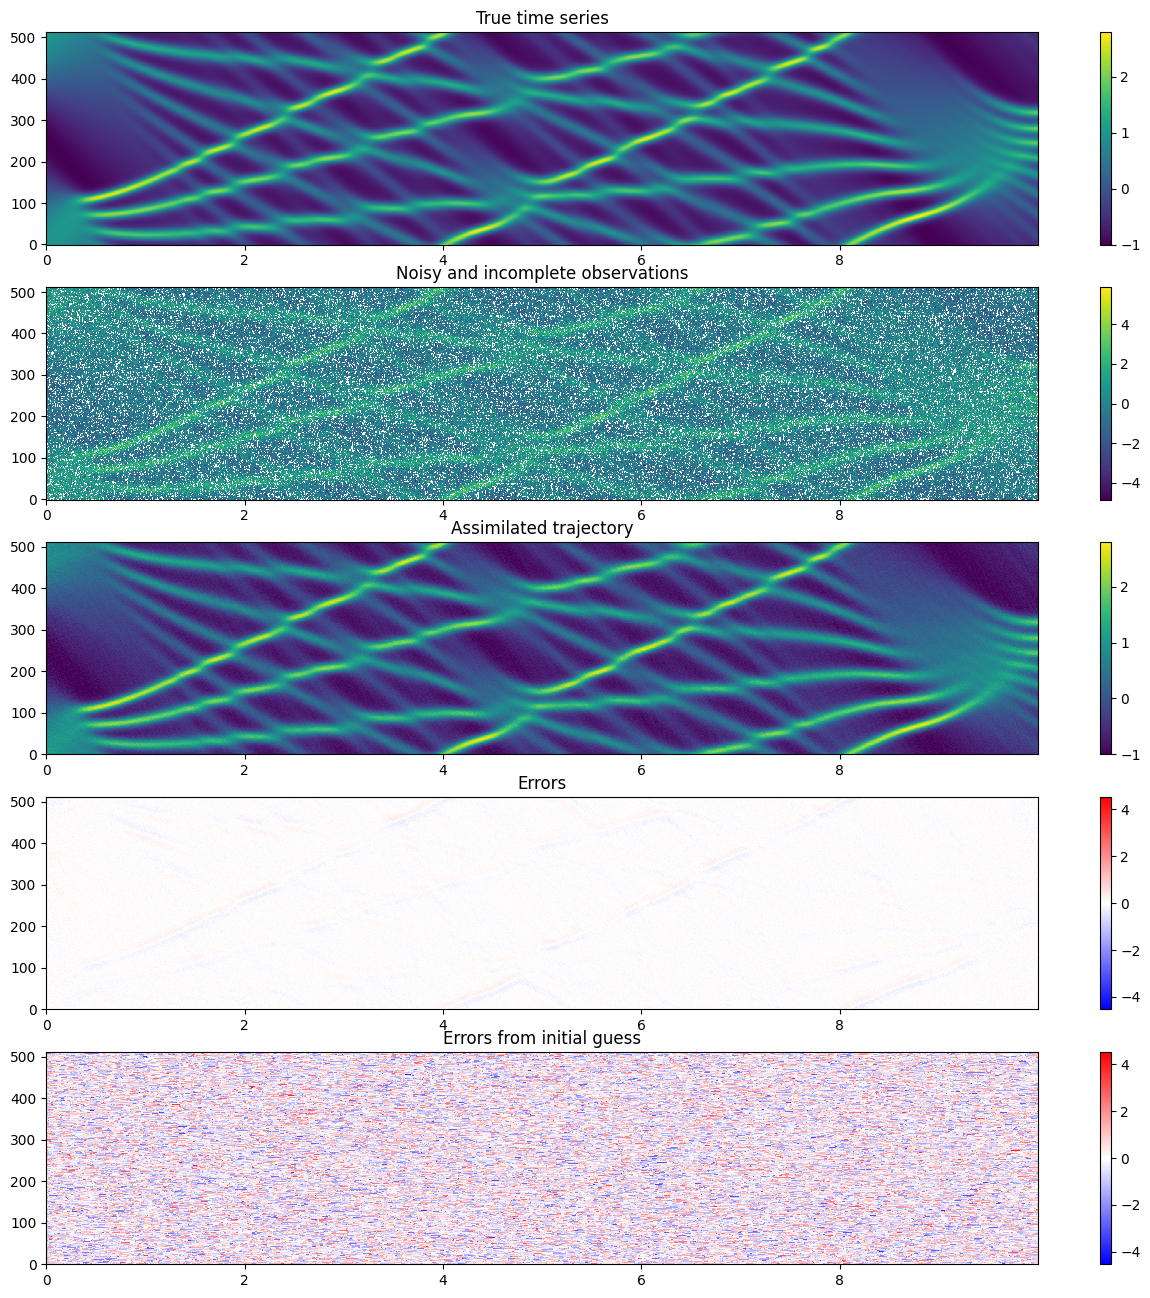

In [ ]:
# We generate the trajectories from the assimilated initial condition and the initial guess to see how they compare with the true trajectory.
error = assimilated_states.fields['x'].detach() - true_series.fields['x']
error_2 = initialization.fields['x'].detach() - true_series.fields['x']
fig, ax = plt.subplots(5, 1, figsize=(16,16))
show_1dseqimg(true_series.fields['x'][0].T, dt=dt, ax=ax[0], title="True time series", vmin=torch.min(true_series.fields['x']), vmax=torch.max(true_series.fields['x']))
show_1dseqimg(valid_obs, dt=dt, ax=ax[1], title="Noisy and incomplete observations")
show_1dseqimg(assimilated_states.fields['x'].detach().squeeze().T, dt=dt, ax=ax[2], vmin=torch.min(true_series.fields['x']), vmax=torch.max(true_series.fields['x']), title="Assimilated trajectory")
show_1dseqimg(error.detach().squeeze().T, dt=dt, ax=ax[3], title="Errors", cmap="bwr", vmin=-torch.max(torch.abs(error_2)), vmax=torch.max(torch.abs(error_2)))
show_1dseqimg(error_2.detach().squeeze().T, dt=dt, ax=ax[4], title="Errors from initial guess", cmap="bwr", vmin=-torch.max(torch.abs(error_2)),  vmax=torch.max(torch.abs(error_2)))

C:\Users\Frion\AppData\Local\Temp\ipykernel_23980\2009511831.py:1: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:3729.)
  RMSE_over_time_assimilated = torch.mean(torch.sqrt((error.T ** 2)), dim=0)


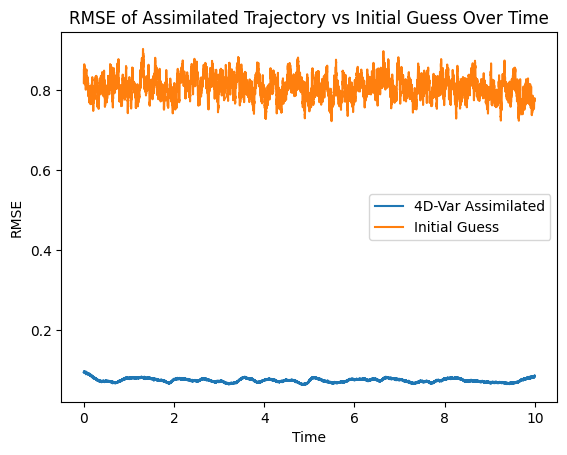

In [ ]:
RMSE_over_time_assimilated = torch.mean(torch.sqrt((error.T ** 2)), dim=0)
RMSE_over_time_initial = torch.mean(torch.sqrt((error_2.T ** 2)), dim=0)

fig, ax = plt.subplots()
plt.plot(forecast_steps, RMSE_over_time_assimilated.squeeze(), label='4D-Var Assimilated')
plt.plot(forecast_steps, RMSE_over_time_initial.squeeze(), label='Initial Guess')
ax.set_xlabel('Time')
ax.set_ylabel('RMSE')
plt.title("RMSE of Assimilated Trajectory vs Initial Guess Over Time")
plt.legend()
plt.show()